# Federated Learning Under Client Heterogeneity

This notebook investigates how **client heterogeneity affects Federated Learning** and explores possible strategies to mitigate its impact.

The experimental pipeline is organized into four main stages:

1. **Experimental setup and data preparation**
2. **Simulation of heterogeneous clients using Dirichlet sampling**
3. **Evaluation of federated learning under different data distributions**
4. **Investigation of mitigation strategies, including alternative federated representations and personalization**

The experiments are designed to isolate the effect of client heterogeneity while keeping the training configuration consistent across scenarios.


In [2]:
# ============================================================
# CELL 1 — IMPORTS
# ============================================================

import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from torchvision import datasets, transforms

from sklearn.metrics import accuracy_score

## 1. Experimental Configuration

The experiment is conducted with **10 simulated clients** over **20 federated communication rounds**.

Client heterogeneity is controlled using different values of the **Dirichlet concentration parameter α**. Smaller values of α generate more heterogeneous, non-IID client data distributions, while larger values produce more similar distributions.

Several additional parameters control the federated training process, the synthetic/statistical representations, and the privacy analysis.

The same configuration is maintained across experiments whenever possible so that the observed differences can be attributed primarily to the experimental factor being studied.


In [3]:
# ============================================================
# CELL 2 — CONFIGURATION
# ============================================================

SEED = 42

# Federated setup
NUM_CLIENTS = 10
NUM_ROUNDS = 20

# Local training
LOCAL_EPOCHS = 1
BATCH_SIZE = 64
LEARNING_RATE = 0.01

# Non-IID levels
# Small alpha = highly heterogeneous
# Large alpha = closer to IID
ALPHAS = [
    0.1,
    0.3,
    0.5,
    1.0,
    5.0,
    10.0
]

# Number of repetitions per alpha
NUM_RUNS = 3

# Dataset
MAX_TRAIN_SAMPLES = 30000

# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Clients:", NUM_CLIENTS)
print("Rounds:", NUM_ROUNDS)
print("Alphas:", ALPHAS)

Device: cpu
Clients: 10
Rounds: 20
Alphas: [0.1, 0.3, 0.5, 1.0, 5.0, 10.0]


In [4]:
# ============================================================
# CELL 3 — REPRODUCIBILITY
# ============================================================

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed(SEED)

In [5]:
# ============================================================
# CELL 4 — LOAD MNIST
# ============================================================

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Original training size:", len(train_dataset))
print("Original test size:", len(test_dataset))

100%|██████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:43<00:00, 227kB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 122kB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:06<00:00, 238kB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 290kB/s]


Original training size: 60000
Original test size: 10000


In [6]:
# ============================================================
# CELL 5 — CONVERT TO NUMPY
# ============================================================

X_full = train_dataset.data.numpy().astype(np.float32) / 255.0
y_full = train_dataset.targets.numpy().astype(np.int64)

X_test = test_dataset.data.numpy().astype(np.float32) / 255.0
y_test = test_dataset.targets.numpy().astype(np.int64)

# Flatten 28x28 images
X_full = X_full.reshape(
    len(X_full),
    -1
)

X_test = X_test.reshape(
    len(X_test),
    -1
)

# Optional subsampling for speed
rng = np.random.default_rng(SEED)

selected_indices = rng.choice(
    len(X_full),
    size=MAX_TRAIN_SAMPLES,
    replace=False
)

X_train = X_full[selected_indices]
y_train = y_full[selected_indices]

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Classes:", np.unique(y_train))

Training shape: (30000, 784)
Test shape: (10000, 784)
Classes: [0 1 2 3 4 5 6 7 8 9]


In [7]:
# ============================================================
# CELL 6 — CLASS DISTRIBUTION
# ============================================================

class_distribution = (
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

print(class_distribution)

0    2976
1    3345
2    2990
3    3069
4    2915
5    2689
6    2981
7    3105
8    2923
9    3007
Name: count, dtype: int64


In [8]:
# ============================================================
# CELL 7 — DIRICHLET PARTITION
# ============================================================

def dirichlet_partition(
    y,
    num_clients,
    alpha,
    seed=42,
    min_samples=10
):
    """
    Partition samples among clients using a Dirichlet distribution.

    alpha:
        small -> strongly non-IID
        large -> closer to IID

    min_samples:
        ensures each client gets at least this many samples.
    """

    rng = np.random.default_rng(seed)

    num_classes = len(np.unique(y))

    client_indices = [
        []
        for _ in range(num_clients)
    ]

    classes = np.unique(y)

    for cls in classes:

        class_indices = np.where(
            y == cls
        )[0]

        rng.shuffle(class_indices)

        proportions = rng.dirichlet(
            np.repeat(
                alpha,
                num_clients
            )
        )

        counts = rng.multinomial(
            len(class_indices),
            proportions
        )

        start = 0

        for client_id, count in enumerate(counts):

            end = start + count

            client_indices[
                client_id
            ].extend(
                class_indices[
                    start:end
                ].tolist()
            )

            start = end

    # --------------------------------------------------------
    # Guarantee minimum samples
    # --------------------------------------------------------

    for client_id in range(num_clients):

        while len(
            client_indices[client_id]
        ) < min_samples:

            largest_client = max(
                range(num_clients),
                key=lambda i:
                    len(client_indices[i])
            )

            moved_sample = (
                client_indices[
                    largest_client
                ].pop()
            )

            client_indices[
                client_id
            ].append(
                moved_sample
            )

    # Shuffle each client
    for client_id in range(num_clients):

        rng.shuffle(
            client_indices[
                client_id
            ]
        )

    return client_indices

In [9]:
# ============================================================
# CELL 8 — HETEROGENEITY METRICS
# ============================================================

def label_distribution(
    labels,
    num_classes=10
):

    counts = np.bincount(
        labels,
        minlength=num_classes
    )

    probabilities = (
        counts / counts.sum()
    )

    return probabilities


def entropy(probabilities):

    p = probabilities[
        probabilities > 0
    ]

    return -np.sum(
        p * np.log2(p)
    )


def kl_divergence(
    p,
    q
):

    mask = p > 0

    return np.sum(
        p[mask]
        * np.log(
            p[mask]
            / np.maximum(
                q[mask],
                1e-12
            )
        )
    )


def js_divergence(
    p,
    q
):

    m = (
        0.5 * (p + q)
    )

    return 0.5 * (
        kl_divergence(p, m)
        +
        kl_divergence(q, m)
    )

In [10]:
# ============================================================
# CELL 9 — CHECK HETEROGENEITY
# ============================================================

partition_info = {}

global_distribution = label_distribution(
    y_train
)

for alpha in ALPHAS:

    indices = dirichlet_partition(
        y_train,
        NUM_CLIENTS,
        alpha,
        seed=SEED
    )

    partition_info[alpha] = indices

    entropy_values = []
    js_values = []

    print("\n" + "=" * 70)
    print(f"ALPHA = {alpha}")
    print("=" * 70)

    for client_id, client_idx in enumerate(indices):

        labels = y_train[
            client_idx
        ]

        client_dist = label_distribution(
            labels
        )

        client_entropy = entropy(
            client_dist
        )

        client_js = js_divergence(
            client_dist,
            global_distribution
        )

        entropy_values.append(
            client_entropy
        )

        js_values.append(
            client_js
        )

        print(
            f"Client {client_id:2d} | "
            f"N={len(client_idx):4d} | "
            f"entropy={client_entropy:.3f} | "
            f"JS={client_js:.3f}"
        )

    print(
        f"\nAverage entropy: "
        f"{np.mean(entropy_values):.3f}"
    )

    print(
        f"Average JS divergence: "
        f"{np.mean(js_values):.3f}"
    )


ALPHA = 0.1
Client  0 | N=3387 | entropy=1.435 | JS=0.354
Client  1 | N=6531 | entropy=2.040 | JS=0.251
Client  2 | N= 133 | entropy=1.534 | JS=0.322
Client  3 | N=2291 | entropy=2.020 | JS=0.252
Client  4 | N=2231 | entropy=1.509 | JS=0.321
Client  5 | N=2238 | entropy=0.967 | JS=0.374
Client  6 | N=5988 | entropy=1.658 | JS=0.311
Client  7 | N=1181 | entropy=0.170 | JS=0.476
Client  8 | N=4232 | entropy=1.741 | JS=0.288
Client  9 | N=1788 | entropy=1.652 | JS=0.306

Average entropy: 1.473
Average JS divergence: 0.325

ALPHA = 0.3
Client  0 | N=3408 | entropy=2.302 | JS=0.211
Client  1 | N=3606 | entropy=2.500 | JS=0.147
Client  2 | N=1039 | entropy=0.819 | JS=0.400
Client  3 | N=2933 | entropy=2.643 | JS=0.132
Client  4 | N=2813 | entropy=1.870 | JS=0.259
Client  5 | N=2118 | entropy=2.386 | JS=0.187
Client  6 | N=2970 | entropy=1.413 | JS=0.340
Client  7 | N=5016 | entropy=2.086 | JS=0.232
Client  8 | N=4109 | entropy=2.487 | JS=0.154
Client  9 | N=1988 | entropy=1.966 | JS=0.235



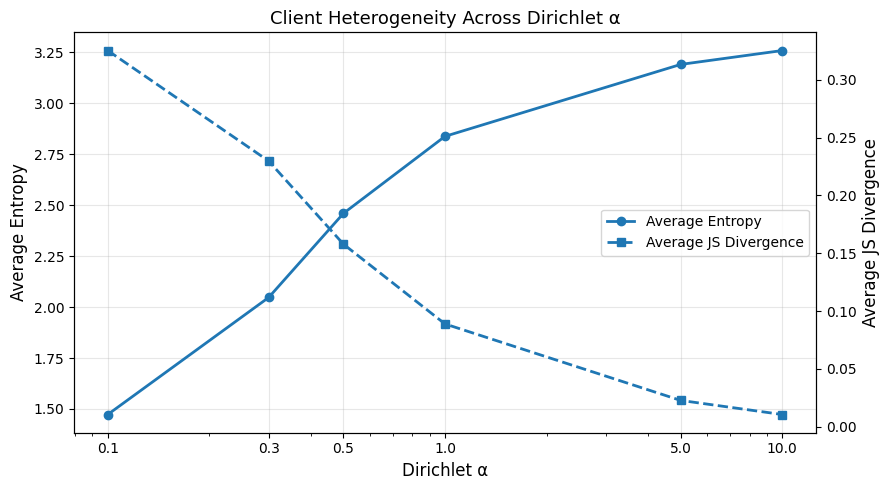

In [87]:
# ============================================================
# PLOT — ENTROPY AND JS DIVERGENCE VS ALPHA
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

avg_entropy_values = []
avg_js_values = []

for alpha in ALPHAS:

    indices = partition_info[alpha]

    entropy_values = []
    js_values = []

    for client_idx in indices:

        labels = y_train[client_idx]

        client_dist = label_distribution(labels)

        client_entropy = entropy(client_dist)

        client_js = js_divergence(
            client_dist,
            global_distribution
        )

        entropy_values.append(client_entropy)
        js_values.append(client_js)

    avg_entropy_values.append(np.mean(entropy_values))
    avg_js_values.append(np.mean(js_values))


# ------------------------------------------------------------
# Same graph with two y-axes
# ------------------------------------------------------------

fig, ax1 = plt.subplots(figsize=(9, 5))

# Entropy
ax1.plot(
    ALPHAS,
    avg_entropy_values,
    marker="o",
    linewidth=2,
    label="Average Entropy"
)

ax1.set_xlabel("Dirichlet α", fontsize=12)
ax1.set_ylabel("Average Entropy", fontsize=12)
ax1.set_xscale("log")

ax1.set_xticks(ALPHAS)
ax1.set_xticklabels(
    [str(alpha) for alpha in ALPHAS]
)

# JS divergence
ax2 = ax1.twinx()

ax2.plot(
    ALPHAS,
    avg_js_values,
    marker="s",
    linewidth=2,
    linestyle="--",
    label="Average JS Divergence"
)

ax2.set_ylabel("Average JS Divergence", fontsize=12)

plt.title(
    "Client Heterogeneity Across Dirichlet α",
    fontsize=13
)

ax1.grid(True, alpha=0.3)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="center right"
)

plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# CELL 10 — MODEL
# ============================================================

class SmallMLP(nn.Module):

    def __init__(
        self,
        input_dim=784,
        num_classes=10
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                num_classes
            )
        )

    def forward(self, x):

        return self.network(x)


def create_model():

    return SmallMLP(
        input_dim=784,
        num_classes=10
    ).to(DEVICE)


model = create_model()

print(model)

SmallMLP(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [12]:
# ============================================================
# CELL 11 — EVALUATION
# ============================================================

def evaluate_model(
    model,
    X,
    y
):

    model.eval()

    X_tensor = torch.tensor(
        X,
        dtype=torch.float32
    ).to(DEVICE)

    y_tensor = torch.tensor(
        y,
        dtype=torch.long
    ).to(DEVICE)

    with torch.no_grad():

        logits = model(
            X_tensor
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

    accuracy = (
        (predictions == y_tensor)
        .float()
        .mean()
        .item()
    )

    return accuracy

In [13]:
# ============================================================
# CELL 12 — LOCAL TRAINING
# ============================================================

def train_local_model(
    global_state,
    X_local,
    y_local
):

    model = create_model()

    model.load_state_dict(
        copy.deepcopy(
            global_state
        )
    )

    dataset = TensorDataset(
        torch.tensor(
            X_local,
            dtype=torch.float32
        ),
        torch.tensor(
            y_local,
            dtype=torch.long
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()

    model.train()

    for _ in range(
        LOCAL_EPOCHS
    ):

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(
                DEVICE
            )

            batch_y = batch_y.to(
                DEVICE
            )

            optimizer.zero_grad()

            logits = model(
                batch_X
            )

            loss = criterion(
                logits,
                batch_y
            )

            loss.backward()

            optimizer.step()

    return {
        k: v.detach().cpu().clone()
        for k, v
        in model.state_dict().items()
    }

In [14]:
# ============================================================
# CELL 13 — FEDAVG
# ============================================================

def fedavg(
    client_states,
    client_sizes
):

    total_samples = sum(
        client_sizes
    )

    global_state = {}

    keys = client_states[
        0
    ].keys()

    for key in keys:

        aggregated = torch.zeros_like(
            client_states[0][key],
            dtype=torch.float32
        )

        for state, size in zip(
            client_states,
            client_sizes
        ):

            weight = (
                size / total_samples
            )

            aggregated += (
                weight
                * state[key].float()
            )

        global_state[key] = (
            aggregated
        )

    return global_state

In [15]:
# ============================================================
# CELL 14 — RUN FEDAVG FOR ONE ALPHA
# ============================================================

def run_fedavg(
    alpha,
    seed=42
):

    set_seed(seed)

    client_indices = (
        dirichlet_partition(
            y_train,
            NUM_CLIENTS,
            alpha,
            seed=seed
        )
    )

    global_model = create_model()

    global_state = {
        k: v.detach().cpu().clone()
        for k, v
        in global_model.state_dict().items()
    }

    history = []

    for round_id in range(
        1,
        NUM_ROUNDS + 1
    ):

        client_states = []
        client_sizes = []

        # ----------------------------------------------------
        # Client training
        # ----------------------------------------------------

        for client_id in range(
            NUM_CLIENTS
        ):

            indices = client_indices[
                client_id
            ]

            X_local = X_train[
                indices
            ]

            y_local = y_train[
                indices
            ]

            local_state = train_local_model(
                global_state,
                X_local,
                y_local
            )

            client_states.append(
                local_state
            )

            client_sizes.append(
                len(indices)
            )

        # ----------------------------------------------------
        # Server aggregation
        # ----------------------------------------------------

        global_state = fedavg(
            client_states,
            client_sizes
        )

        global_model.load_state_dict(
            global_state
        )

        # ----------------------------------------------------
        # Global test accuracy
        # ----------------------------------------------------

        global_accuracy = evaluate_model(
            global_model,
            X_test,
            y_test
        )

        # ----------------------------------------------------
        # Client accuracies
        # ----------------------------------------------------

        client_accuracies = []

        for client_id in range(
            NUM_CLIENTS
        ):

            indices = client_indices[
                client_id
            ]

            acc = evaluate_model(
                global_model,
                X_train[indices],
                y_train[indices]
            )

            client_accuracies.append(
                acc
            )

        history.append({

            "round": round_id,

            "global_accuracy":
                global_accuracy,

            "mean_client_accuracy":
                np.mean(
                    client_accuracies
                ),

            "std_client_accuracy":
                np.std(
                    client_accuracies
                ),

            "worst_client_accuracy":
                np.min(
                    client_accuracies
                )
        })

    return {
        "alpha": alpha,
        "history": pd.DataFrame(
            history
        ),
        "model": global_model,
        "client_indices": client_indices
    }

In [16]:
# ============================================================
# CELL 15 — SANITY CHECK
# ============================================================

start = time.time()

test_result = run_fedavg(
    alpha=0.5,
    seed=SEED
)

elapsed = time.time() - start

print(
    f"Experiment completed in "
    f"{elapsed:.2f} seconds"
)

print(
    test_result["history"].tail()
)

Experiment completed in 32.98 seconds
    round  global_accuracy  mean_client_accuracy  std_client_accuracy  \
15     16           0.8281              0.812689             0.093892   
16     17           0.8334              0.819126             0.086771   
17     18           0.8372              0.824707             0.080968   
18     19           0.8421              0.830374             0.075358   
19     20           0.8467              0.834969             0.072524   

    worst_client_accuracy  
15               0.563810  
16               0.589714  
17               0.609905  
18               0.630857  
19               0.643048  


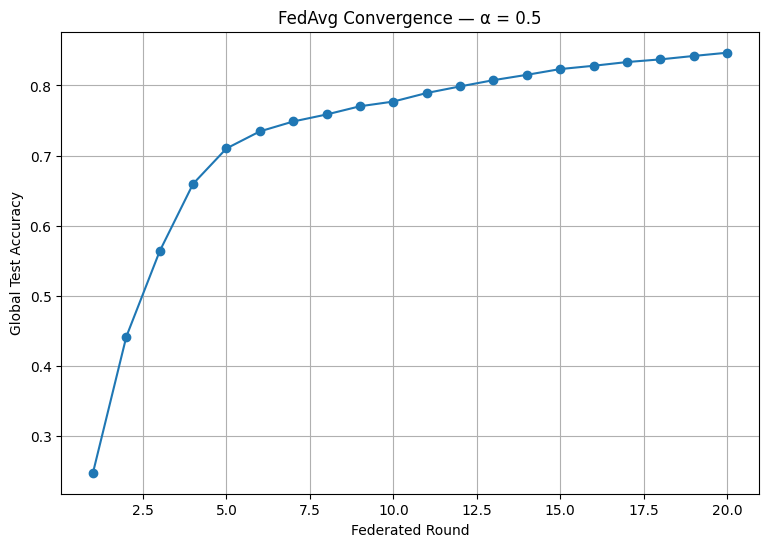

In [17]:
# ============================================================
# CELL 16 — SANITY-CHECK CURVE
# ============================================================

history = test_result["history"]

plt.figure(figsize=(9, 6))

plt.plot(
    history["round"],
    history["global_accuracy"],
    marker="o"
)

plt.xlabel("Federated Round")
plt.ylabel("Global Test Accuracy")

plt.title(
    "FedAvg Convergence — α = 0.5"
)

plt.grid(True)

plt.show()

In [18]:
# ============================================================
# CELL 17 — FULL EXPERIMENT
# ============================================================

all_experiment_results = []

total_start = time.time()

for alpha in ALPHAS:

    print("\n")
    print("=" * 70)
    print(f"ALPHA = {alpha}")
    print("=" * 70)

    for run in range(NUM_RUNS):

        seed = (
            SEED
            + run
        )

        print(
            f"Run {run + 1}/{NUM_RUNS}..."
        )

        start = time.time()

        result = run_fedavg(
            alpha=alpha,
            seed=seed
        )

        elapsed = (
            time.time() - start
        )

        history = result[
            "history"
        ]

        history[
            "alpha"
        ] = alpha

        history[
            "run"
        ] = run

        all_experiment_results.append(
            history
        )

        print(
            f"Final accuracy: "
            f"{history['global_accuracy'].iloc[-1]:.4f}"
        )

        print(
            f"Time: "
            f"{elapsed:.1f} sec"
        )

total_elapsed = (
    time.time() - total_start
)

print("\n")
print("=" * 70)

print(
    f"TOTAL EXPERIMENT TIME: "
    f"{total_elapsed / 60:.2f} minutes"
)



ALPHA = 0.1
Run 1/3...
Final accuracy: 0.7810
Time: 32.8 sec
Run 2/3...
Final accuracy: 0.7546
Time: 33.4 sec
Run 3/3...
Final accuracy: 0.8106
Time: 34.1 sec


ALPHA = 0.3
Run 1/3...
Final accuracy: 0.8129
Time: 35.2 sec
Run 2/3...
Final accuracy: 0.8409
Time: 34.2 sec
Run 3/3...
Final accuracy: 0.8057
Time: 34.7 sec


ALPHA = 0.5
Run 1/3...
Final accuracy: 0.8467
Time: 35.0 sec
Run 2/3...
Final accuracy: 0.8665
Time: 35.3 sec
Run 3/3...
Final accuracy: 0.8588
Time: 35.6 sec


ALPHA = 1.0
Run 1/3...
Final accuracy: 0.8621
Time: 35.7 sec
Run 2/3...
Final accuracy: 0.8687
Time: 34.0 sec
Run 3/3...
Final accuracy: 0.8622
Time: 33.8 sec


ALPHA = 5.0
Run 1/3...
Final accuracy: 0.8648
Time: 34.8 sec
Run 2/3...
Final accuracy: 0.8673
Time: 35.5 sec
Run 3/3...
Final accuracy: 0.8664
Time: 34.3 sec


ALPHA = 10.0
Run 1/3...
Final accuracy: 0.8646
Time: 34.2 sec
Run 2/3...
Final accuracy: 0.8670
Time: 35.1 sec
Run 3/3...
Final accuracy: 0.8648
Time: 33.4 sec


TOTAL EXPERIMENT TIME: 10.36 mi

In [84]:
# ============================================================
# CELL 18 — COMBINE RESULTS
# ============================================================

experiment_df = pd.concat(
    all_experiment_results,
    ignore_index=True
)

experiment_df.head(100
                  )

,round,global_accuracy,mean_client_accuracy,std_client_accuracy,worst_client_accuracy,alpha,run
0,1,0.3357,0.276027,0.190203,0.036307,0.1,0
1,2,0.3880,0.380170,0.211731,0.109368,0.1,0
2,3,0.4390,0.446453,0.217210,0.134048,0.1,0
3,4,0.5011,0.504345,0.214018,0.144772,0.1,0
4,5,0.5616,0.568285,0.208779,0.153709,0.1,0
...,...,...,...,...,...,...,...
95,16,0.8240,0.825766,0.083460,0.664221,0.3,1
96,17,0.8302,0.829725,0.080126,0.668623,0.3,1
97,18,0.8357,0.835627,0.075361,0.680657,0.3,1
98,19,0.8363,0.837292,0.075410,0.685941,0.3,1


In [20]:
# ============================================================
# CELL 19 — MEAN CONVERGENCE
# ============================================================

mean_history = (
    experiment_df
    .groupby(
        ["alpha", "round"]
    )
    .agg(
        mean_accuracy=(
            "global_accuracy",
            "mean"
        ),

        std_accuracy=(
            "global_accuracy",
            "std"
        ),

        mean_client_accuracy=(
            "mean_client_accuracy",
            "mean"
        ),

        worst_client_accuracy=(
            "worst_client_accuracy",
            "mean"
        )
    )
    .reset_index()
)

mean_history.head()

,alpha,round,mean_accuracy,std_accuracy,mean_client_accuracy,worst_client_accuracy
0,0.1,1,0.315867,0.026401,0.250861,0.017409
1,0.1,2,0.394233,0.039025,0.354607,0.043281
2,0.1,3,0.453467,0.074264,0.422130,0.102743
3,0.1,4,0.504700,0.082259,0.471537,0.143801
4,0.1,5,0.563033,0.081259,0.534212,0.184702


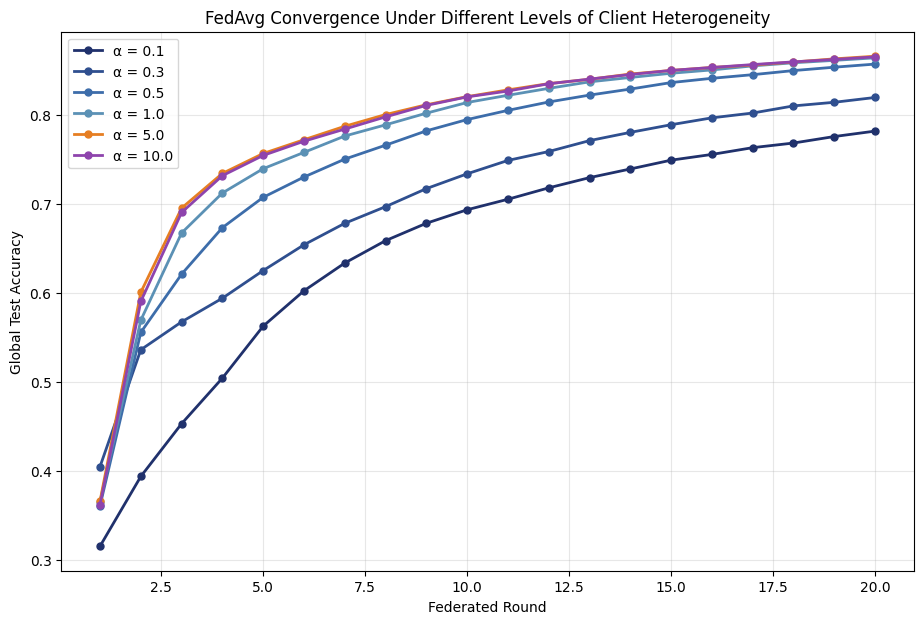

In [90]:
# ============================================================
# CELL 20 — MAIN CONVERGENCE PLOT
# ============================================================

colors = {
    0.1: "#20316c",   # Dark navy
    0.3: "#2f4f8f",   # Deep blue
    0.5: "#3d6daa",   # Main blue
    1:   "#5b91b5",   # Light blue
    5:   "#E67E22",   # Orange
    10:  "#8E44AD"    # Purple
}

plt.figure(figsize=(11, 7))

for alpha in ALPHAS:

    subset = mean_history[
        mean_history["alpha"] == alpha
    ]

    plt.plot(
        subset["round"],
        subset["mean_accuracy"],
        marker="o",
        color=colors[alpha],
        linewidth=2,
        markersize=5,
        label=f"α = {alpha}"
    )

plt.xlabel("Federated Round")
plt.ylabel("Global Test Accuracy")

plt.title(
    "FedAvg Convergence Under Different Levels of Client Heterogeneity"
)

plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

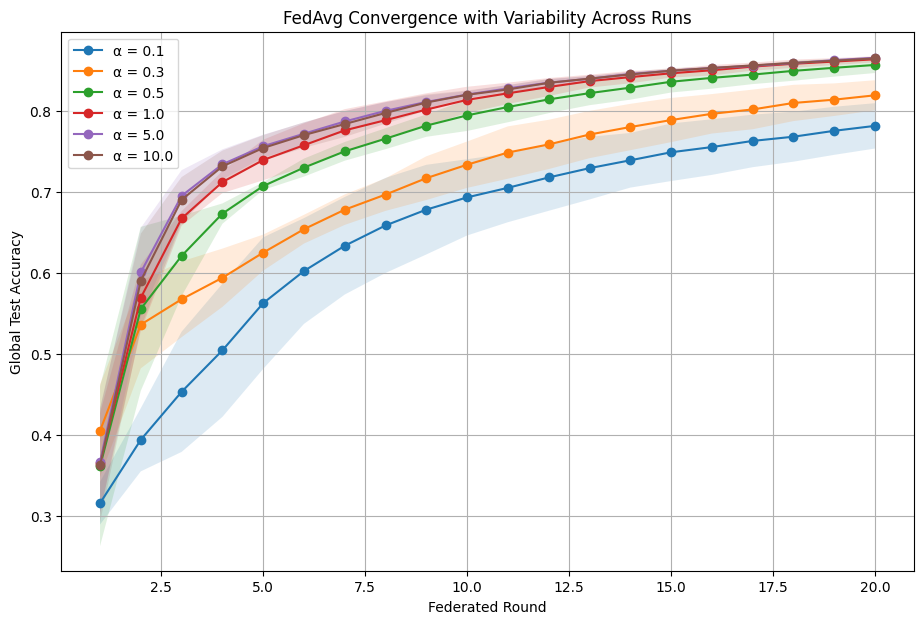

In [22]:
# ============================================================
# CELL 21 — CONVERGENCE WITH VARIABILITY
# ============================================================

plt.figure(figsize=(11, 7))

for alpha in ALPHAS:

    subset = mean_history[
        mean_history["alpha"] == alpha
    ]

    x = subset["round"].values

    mean = subset[
        "mean_accuracy"
    ].values

    std = subset[
        "std_accuracy"
    ].values

    plt.plot(
        x,
        mean,
        marker="o",
        label=f"α = {alpha}"
    )

    plt.fill_between(
        x,
        mean - std,
        mean + std,
        alpha=0.15
    )

plt.xlabel(
    "Federated Round"
)

plt.ylabel(
    "Global Test Accuracy"
)

plt.title(
    "FedAvg Convergence with Variability Across Runs"
)

plt.grid(True)
plt.legend()

plt.show()

In [23]:
# ============================================================
# CELL 22 — FINAL PERFORMANCE
# ============================================================

final_results = (
    experiment_df[
        experiment_df["round"] == NUM_ROUNDS
    ]
    .groupby("alpha")
    .agg(

        final_accuracy=(
            "global_accuracy",
            "mean"
        ),

        final_accuracy_std=(
            "global_accuracy",
            "std"
        ),

        final_mean_client_accuracy=(
            "mean_client_accuracy",
            "mean"
        ),

        final_worst_client_accuracy=(
            "worst_client_accuracy",
            "mean"
        )
    )
    .reset_index()
)

final_results

,alpha,final_accuracy,final_accuracy_std,final_mean_client_accuracy,final_worst_client_accuracy
0,0.1,0.782067,0.028015,0.749267,0.403806
1,0.3,0.819833,0.018596,0.797872,0.576162
2,0.5,0.857333,0.009981,0.851227,0.718932
3,1.0,0.864333,0.003782,0.858016,0.824862
4,5.0,0.866167,0.001266,0.860359,0.845017
5,10.0,0.865467,0.001332,0.859886,0.846630


In [24]:
# ============================================================
# CELL 23 — ROUNDS TO TARGET ACCURACY
# ============================================================

TARGET_ACCURACY = 0.80


def rounds_to_target(
    history,
    target=0.80
):

    reached = history[
        history["global_accuracy"] >= target
    ]

    if len(reached) == 0:

        return np.nan

    return reached[
        "round"
    ].iloc[0]


speed_rows = []

for alpha in ALPHAS:

    for run in range(NUM_RUNS):

        history = experiment_df[
            (experiment_df["alpha"] == alpha)
            &
            (experiment_df["run"] == run)
        ]

        rounds = rounds_to_target(
            history,
            TARGET_ACCURACY
        )

        speed_rows.append({
            "alpha": alpha,
            "run": run,
            "rounds_to_80":
                rounds
        })


speed_df = pd.DataFrame(
    speed_rows
)

speed_summary = (
    speed_df
    .groupby("alpha")
    .agg(
        mean_rounds_to_80=(
            "rounds_to_80",
            "mean"
        ),

        std_rounds_to_80=(
            "rounds_to_80",
            "std"
        )
    )
    .reset_index()
)

speed_summary

,alpha,mean_rounds_to_80,std_rounds_to_80
0,0.1,19.000000,NaN
1,0.3,17.000000,3.605551
2,0.5,11.333333,1.527525
3,1.0,9.000000,2.000000
4,5.0,8.333333,0.577350
5,10.0,8.666667,1.154701


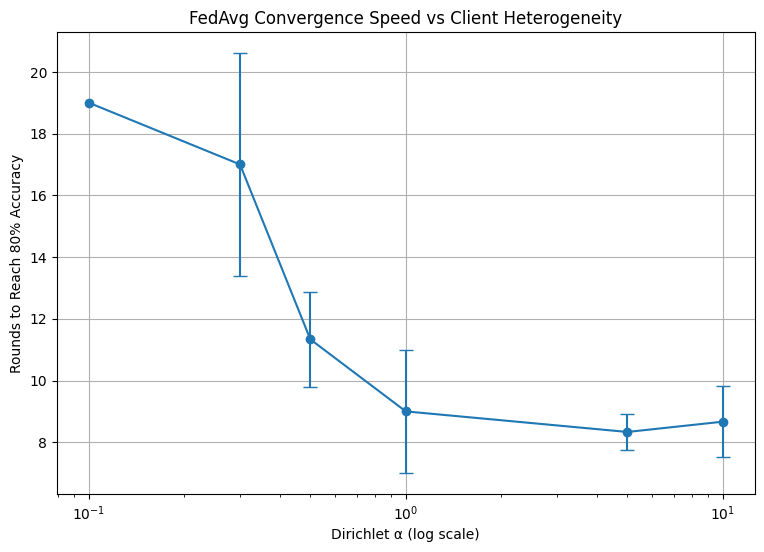

In [25]:
# ============================================================
# CELL 24 — CONVERGENCE SPEED
# ============================================================

plt.figure(figsize=(9, 6))

plt.errorbar(
    speed_summary["alpha"],
    speed_summary["mean_rounds_to_80"],
    yerr=speed_summary["std_rounds_to_80"],
    marker="o",
    capsize=5
)

plt.xscale("log")

plt.xlabel(
    "Dirichlet α (log scale)"
)

plt.ylabel(
    "Rounds to Reach 80% Accuracy"
)

plt.title(
    "FedAvg Convergence Speed vs Client Heterogeneity"
)

plt.grid(True)

plt.show()

In [26]:
# ============================================================
# CELL 25 — HETEROGENEITY SUMMARY
# ============================================================

heterogeneity_rows = []

for alpha in ALPHAS:

    indices = dirichlet_partition(
        y_train,
        NUM_CLIENTS,
        alpha,
        seed=SEED
    )

    entropy_values = []
    js_values = []

    for client_idx in indices:

        client_labels = y_train[
            client_idx
        ]

        client_dist = label_distribution(
            client_labels
        )

        entropy_values.append(
            entropy(client_dist)
        )

        js_values.append(
            js_divergence(
                client_dist,
                global_distribution
            )
        )

    heterogeneity_rows.append({

        "alpha": alpha,

        "mean_client_entropy":
            np.mean(entropy_values),

        "mean_JS_divergence":
            np.mean(js_values)
    })


heterogeneity_df = pd.DataFrame(
    heterogeneity_rows
)

heterogeneity_df

,alpha,mean_client_entropy,mean_JS_divergence
0,0.1,1.472549,0.325385
1,0.3,2.047117,0.229795
2,0.5,2.460140,0.157827
3,1.0,2.838101,0.088822
4,5.0,3.191192,0.022651
5,10.0,3.259341,0.010449


In [27]:
# ============================================================
# CELL 26 — COMBINED RESULTS
# ============================================================

research_results = (
    final_results
    .merge(
        speed_summary,
        on="alpha",
        how="left"
    )
    .merge(
        heterogeneity_df,
        on="alpha",
        how="left"
    )
)

research_results

,alpha,final_accuracy,final_accuracy_std,final_mean_client_accuracy,final_worst_client_accuracy,mean_rounds_to_80,std_rounds_to_80,mean_client_entropy,mean_JS_divergence
0,0.1,0.782067,0.028015,0.749267,0.403806,19.000000,NaN,1.472549,0.325385
1,0.3,0.819833,0.018596,0.797872,0.576162,17.000000,3.605551,2.047117,0.229795
2,0.5,0.857333,0.009981,0.851227,0.718932,11.333333,1.527525,2.460140,0.157827
3,1.0,0.864333,0.003782,0.858016,0.824862,9.000000,2.000000,2.838101,0.088822
4,5.0,0.866167,0.001266,0.860359,0.845017,8.333333,0.577350,3.191192,0.022651
5,10.0,0.865467,0.001332,0.859886,0.846630,8.666667,1.154701,3.259341,0.010449


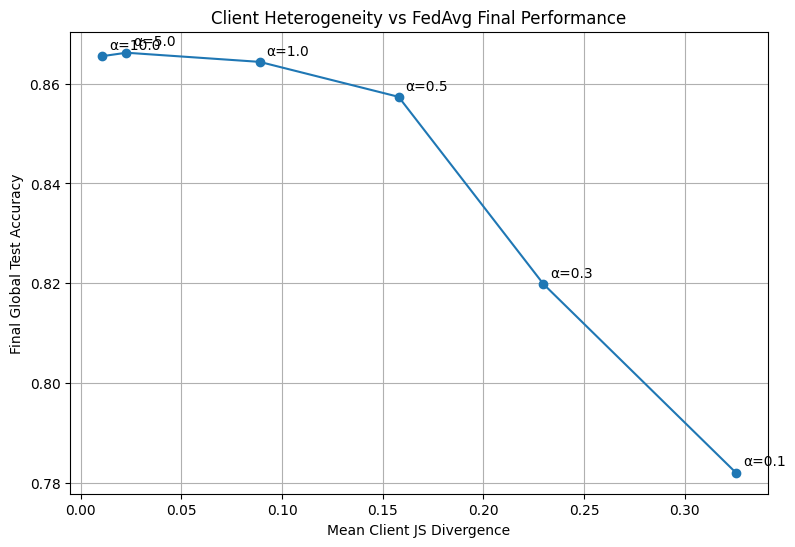

In [28]:
# ============================================================
# CELL 27 — HETEROGENEITY VS FINAL ACCURACY
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    research_results[
        "mean_JS_divergence"
    ],
    research_results[
        "final_accuracy"
    ],
    marker="o"
)

for _, row in research_results.iterrows():

    plt.annotate(
        f"α={row['alpha']}",
        (
            row["mean_JS_divergence"],
            row["final_accuracy"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(
    "Mean Client JS Divergence"
)

plt.ylabel(
    "Final Global Test Accuracy"
)

plt.title(
    "Client Heterogeneity vs FedAvg Final Performance"
)

plt.grid(True)

plt.show()

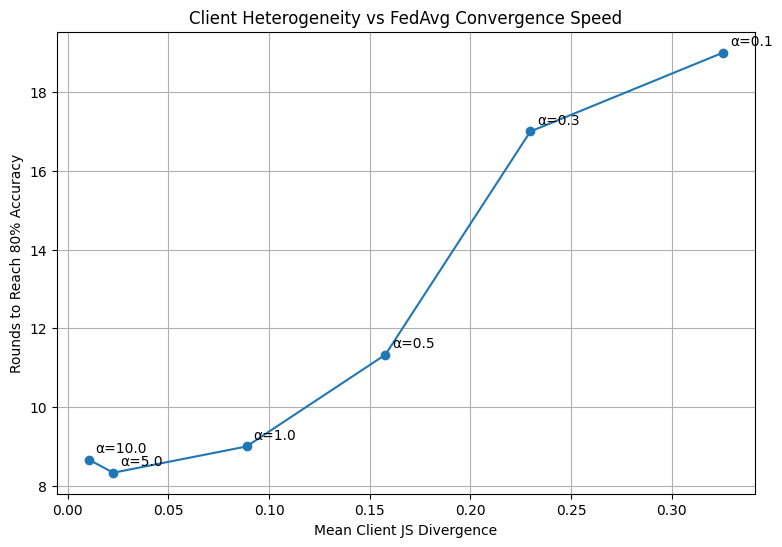

In [29]:
# ============================================================
# CELL 28 — HETEROGENEITY VS CONVERGENCE SPEED
# ============================================================

valid = research_results.dropna(
    subset=[
        "mean_JS_divergence",
        "mean_rounds_to_80"
    ]
)

plt.figure(figsize=(9, 6))

plt.plot(
    valid["mean_JS_divergence"],
    valid["mean_rounds_to_80"],
    marker="o"
)

for _, row in valid.iterrows():

    plt.annotate(
        f"α={row['alpha']}",
        (
            row["mean_JS_divergence"],
            row["mean_rounds_to_80"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(
    "Mean Client JS Divergence"
)

plt.ylabel(
    "Rounds to Reach 80% Accuracy"
)

plt.title(
    "Client Heterogeneity vs FedAvg Convergence Speed"
)

plt.grid(True)

plt.show()

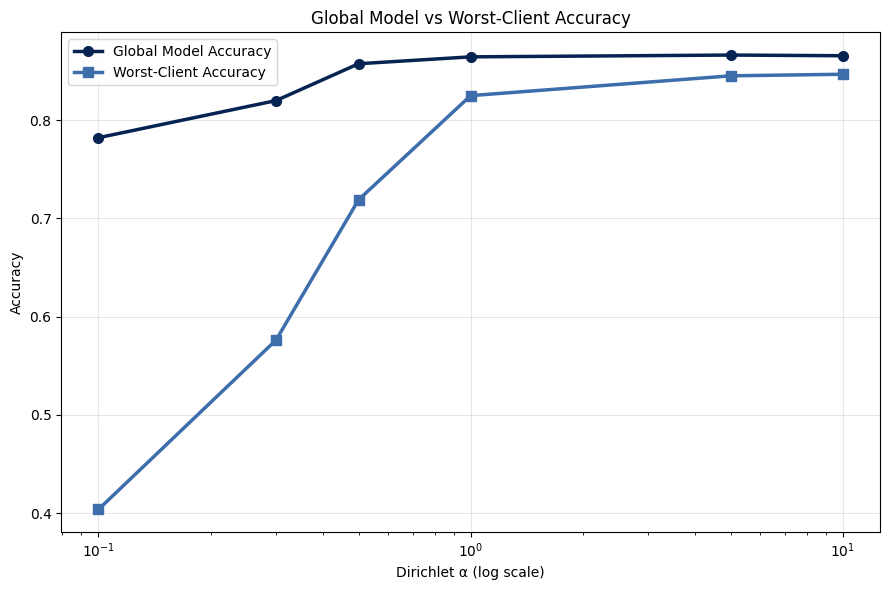

In [94]:
# ============================================================
# CELL 29 — GLOBAL MODEL vs WORST-CLIENT PERFORMANCE
# ============================================================

plt.figure(figsize=(9, 6))

# ------------------------------------------------------------
# GLOBAL MODEL ACCURACY
# ------------------------------------------------------------

plt.plot(
    research_results["alpha"],
    research_results["final_accuracy"],
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="#062351",
    label="Global Model Accuracy"
)

# ------------------------------------------------------------
# WORST-CLIENT ACCURACY
# ------------------------------------------------------------

plt.plot(
    research_results["alpha"],
    research_results["final_worst_client_accuracy"],
    marker="s",
    linewidth=2.5,
    markersize=7,
    color="#3d6daa",
    label="Worst-Client Accuracy"
)

# ------------------------------------------------------------
# AXIS
# ------------------------------------------------------------

plt.xscale("log")

plt.xlabel(
    "Dirichlet α (log scale)"
)

plt.ylabel(
    "Accuracy"
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

plt.title(
    "Global Model vs Worst-Client Accuracy"
)

# ------------------------------------------------------------
# GRID + LEGEND
# ------------------------------------------------------------

plt.grid(
    True,
    alpha=0.3
)

plt.legend(
    loc="best"
)

plt.tight_layout()

plt.show()

In [31]:
# ============================================================
# CELL 30 — FINAL TABLE
# ============================================================

final_display = research_results.copy()

final_display[
    "final_accuracy"
] = final_display[
    "final_accuracy"
].round(4)

final_display[
    "final_accuracy_std"
] = final_display[
    "final_accuracy_std"
].round(4)

final_display[
    "final_worst_client_accuracy"
] = final_display[
    "final_worst_client_accuracy"
].round(4)

final_display[
    "mean_rounds_to_80"
] = final_display[
    "mean_rounds_to_80"
].round(2)

final_display[
    "mean_JS_divergence"
] = final_display[
    "mean_JS_divergence"
].round(4)

final_display

,alpha,final_accuracy,final_accuracy_std,final_mean_client_accuracy,final_worst_client_accuracy,mean_rounds_to_80,std_rounds_to_80,mean_client_entropy,mean_JS_divergence
0,0.1,0.7821,0.0280,0.749267,0.4038,19.00,NaN,1.472549,0.3254
1,0.3,0.8198,0.0186,0.797872,0.5762,17.00,3.605551,2.047117,0.2298
2,0.5,0.8573,0.0100,0.851227,0.7189,11.33,1.527525,2.460140,0.1578
3,1.0,0.8643,0.0038,0.858016,0.8249,9.00,2.000000,2.838101,0.0888
4,5.0,0.8662,0.0013,0.860359,0.8450,8.33,0.577350,3.191192,0.0227
5,10.0,0.8655,0.0013,0.859886,0.8466,8.67,1.154701,3.259341,0.0104


In [32]:
# ============================================================
# CELL 31 — SAVE RESULTS
# ============================================================

experiment_df.to_csv(
    "fedavg_heterogeneity_all_rounds.csv",
    index=False
)

research_results.to_csv(
    "fedavg_heterogeneity_final_results.csv",
    index=False
)

speed_summary.to_csv(
    "fedavg_convergence_speed.csv",
    index=False
)

heterogeneity_df.to_csv(
    "client_heterogeneity.csv",
    index=False
)

print("Results saved.")

Results saved.


In [50]:
# ============================================================
# CELL 32 — PERSONALIZATION CONFIGURATION
# ============================================================

PERSONALIZATION_EPOCHS = 3
PERSONALIZATION_LR = 0.005

CLIENT_TEST_RATIO = 0.20

TARGET_ACCURACY = 0.80

print("Personalization epochs:", PERSONALIZATION_EPOCHS)
print("Personalization LR:", PERSONALIZATION_LR)
print("Client test ratio:", CLIENT_TEST_RATIO)

Personalization epochs: 3
Personalization LR: 0.005
Client test ratio: 0.2


In [51]:
# ============================================================
# CELL 33 — CLIENT TRAIN / TEST SPLIT
# ============================================================

def create_client_train_test_splits(
    y,
    num_clients,
    alpha,
    test_ratio=0.20,
    seed=42
):
    """
    1. Create heterogeneous clients using Dirichlet sampling.
    2. Split each client's data into:
           - local training data
           - local test data
    """

    # --------------------------------------------------------
    # Create heterogeneous client partitions
    # --------------------------------------------------------

    client_indices = dirichlet_partition(
        y=y,
        num_clients=num_clients,
        alpha=alpha,
        seed=seed
    )

    rng = np.random.default_rng(seed)

    client_train_indices = {}
    client_test_indices = {}

    # --------------------------------------------------------
    # Split each client independently
    # --------------------------------------------------------

    for client_id in range(num_clients):

        indices = np.array(
            client_indices[client_id]
        )

        rng.shuffle(indices)

        split_point = int(
            len(indices)
            * (1 - test_ratio)
        )

        train_indices = indices[
            :split_point
        ]

        test_indices = indices[
            split_point:
        ]

        client_train_indices[
            client_id
        ] = train_indices.tolist()

        client_test_indices[
            client_id
        ] = test_indices.tolist()

    return (
        client_train_indices,
        client_test_indices
    )

In [52]:
# ============================================================
# CELL 34 — INSPECT CLIENT SPLITS
# ============================================================

train_indices, test_indices = (
    create_client_train_test_splits(
        y_train,
        NUM_CLIENTS,
        alpha=0.1,
        test_ratio=CLIENT_TEST_RATIO,
        seed=SEED
    )
)

for client_id in range(NUM_CLIENTS):

    print(
        f"Client {client_id:2d} | "
        f"train = {len(train_indices[client_id]):4d} | "
        f"test = {len(test_indices[client_id]):4d}"
    )

Client  0 | train = 2709 | test =  678
Client  1 | train = 5224 | test = 1307
Client  2 | train =  106 | test =   27
Client  3 | train = 1832 | test =  459
Client  4 | train = 1784 | test =  447
Client  5 | train = 1790 | test =  448
Client  6 | train = 4790 | test = 1198
Client  7 | train =  944 | test =  237
Client  8 | train = 3385 | test =  847
Client  9 | train = 1430 | test =  358


In [53]:
# ============================================================
# CELL 35 — CLIENT-SPECIFIC EVALUATION
# ============================================================

def evaluate_client_model(
    model,
    indices
):
    """
    Evaluate a model on a client's held-out test set.
    """

    X_client = X_train[
        indices
    ]

    y_client = y_train[
        indices
    ]

    return evaluate_model(
        model,
        X_client,
        y_client
    )

In [54]:
# ============================================================
# CELL 36 — PERSONALIZATION TRAINING
# ============================================================

def personalize_model(
    global_state,
    X_local,
    y_local,
    epochs=3,
    learning_rate=0.005
):
    """
    Start from the global model and fine-tune it
    on one client's local training data.
    """

    model = create_model()

    # Start from the global model
    model.load_state_dict(
        copy.deepcopy(
            global_state
        )
    )

    dataset = TensorDataset(
        torch.tensor(
            X_local,
            dtype=torch.float32
        ),
        torch.tensor(
            y_local,
            dtype=torch.long
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    criterion = nn.CrossEntropyLoss()

    model.train()

    for _ in range(epochs):

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(
                DEVICE
            )

            batch_y = batch_y.to(
                DEVICE
            )

            optimizer.zero_grad()

            logits = model(
                batch_X
            )

            loss = criterion(
                logits,
                batch_y
            )

            loss.backward()

            optimizer.step()

    return model

In [55]:
# ============================================================
# CELL 37 — FEDAVG WITH HELD-OUT CLIENT TEST SETS
# ============================================================

def run_fedavg_for_personalization(
    alpha,
    seed=42
):
    """
    Train standard FedAvg using only each client's
    local training data.

    Each client's held-out test data is never used
    during federated training.
    """

    set_seed(seed)

    # --------------------------------------------------------
    # Create heterogeneous clients
    # --------------------------------------------------------

    (
        client_train_indices,
        client_test_indices
    ) = create_client_train_test_splits(
        y=y_train,
        num_clients=NUM_CLIENTS,
        alpha=alpha,
        test_ratio=CLIENT_TEST_RATIO,
        seed=seed
    )

    # --------------------------------------------------------
    # Initialize global model
    # --------------------------------------------------------

    global_model = create_model()

    global_state = {
        k: v.detach().cpu().clone()
        for k, v in global_model.state_dict().items()
    }

    history = []

    # --------------------------------------------------------
    # Federated training
    # --------------------------------------------------------

    for round_id in range(
        1,
        NUM_ROUNDS + 1
    ):

        client_states = []
        client_sizes = []

        # ----------------------------------------------------
        # Local client training
        # ----------------------------------------------------

        for client_id in range(
            NUM_CLIENTS
        ):

            indices = client_train_indices[
                client_id
            ]

            X_local = X_train[
                indices
            ]

            y_local = y_train[
                indices
            ]

            local_state = train_local_model(
                global_state,
                X_local,
                y_local
            )

            client_states.append(
                local_state
            )

            client_sizes.append(
                len(indices)
            )

        # ----------------------------------------------------
        # FedAvg aggregation
        # ----------------------------------------------------

        global_state = fedavg(
            client_states,
            client_sizes
        )

        global_model.load_state_dict(
            global_state
        )

        # ----------------------------------------------------
        # Global test accuracy
        # ----------------------------------------------------

        global_accuracy = evaluate_model(
            global_model,
            X_test,
            y_test
        )

        # ----------------------------------------------------
        # Held-out client performance
        # ----------------------------------------------------

        client_accuracies = []

        for client_id in range(
            NUM_CLIENTS
        ):

            test_indices = client_test_indices[
                client_id
            ]

            acc = evaluate_client_model(
                global_model,
                test_indices
            )

            client_accuracies.append(
                acc
            )

        history.append({

            "round": round_id,

            "global_accuracy":
                global_accuracy,

            "mean_client_accuracy":
                np.mean(
                    client_accuracies
                ),

            "std_client_accuracy":
                np.std(
                    client_accuracies
                ),

            "worst_client_accuracy":
                np.min(
                    client_accuracies
                )
        })

    return {

        "alpha": alpha,

        "global_model":
            global_model,

        "global_state":
            global_state,

        "history":
            pd.DataFrame(history),

        "client_train_indices":
            client_train_indices,

        "client_test_indices":
            client_test_indices
    }

In [56]:
# ============================================================
# CELL 38 — TEST FEDAVG WITH HELD-OUT CLIENT TEST SETS
# ============================================================

start = time.time()

fedavg_personalization_test = (
    run_fedavg_for_personalization(
        alpha=0.5,
        seed=SEED
    )
)

elapsed = time.time() - start

print(
    f"FedAvg completed in "
    f"{elapsed:.2f} seconds"
)

print(
    fedavg_personalization_test[
        "history"
    ].tail()
)

FedAvg completed in 17.93 seconds
    round  global_accuracy  mean_client_accuracy  std_client_accuracy  \
15     16           0.8055              0.790307             0.112834   
16     17           0.8153              0.800451             0.102715   
17     18           0.8214              0.805389             0.096985   
18     19           0.8282              0.812555             0.091386   
19     20           0.8335              0.820917             0.082821   

    worst_client_accuracy  
15               0.495238  
16               0.533333  
17               0.552381  
18               0.573333  
19               0.605714  


In [57]:
# ============================================================
# CELL 39 — PERSONALIZE ONE CLIENT
# ============================================================

client_id = 0

global_state = (
    fedavg_personalization_test[
        "global_state"
    ]
)

client_train_indices = (
    fedavg_personalization_test[
        "client_train_indices"
    ]
)

client_test_indices = (
    fedavg_personalization_test[
        "client_test_indices"
    ]
)

# ------------------------------------------------------------
# Performance BEFORE personalization
# ------------------------------------------------------------

before_accuracy = evaluate_client_model(
    fedavg_personalization_test[
        "global_model"
    ],
    client_test_indices[
        client_id
    ]
)

# ------------------------------------------------------------
# Create personalized model
# ------------------------------------------------------------

personalized_model = personalize_model(

    global_state,

    X_train[
        client_train_indices[
            client_id
        ]
    ],

    y_train[
        client_train_indices[
            client_id
        ]
    ],

    epochs=PERSONALIZATION_EPOCHS,

    learning_rate=PERSONALIZATION_LR
)

# ------------------------------------------------------------
# Performance AFTER personalization
# ------------------------------------------------------------

after_accuracy = evaluate_client_model(
    personalized_model,
    client_test_indices[
        client_id
    ]
)

print(
    f"Client {client_id}"
)

print(
    f"Before personalization: "
    f"{before_accuracy:.4f}"
)

print(
    f"After personalization:  "
    f"{after_accuracy:.4f}"
)

Client 0
Before personalization: 0.8715
After personalization:  0.9193


In [58]:
# ============================================================
# CELL 40 — PERSONALIZE ALL CLIENTS
# ============================================================

def personalize_all_clients(
    global_state,
    client_train_indices,
    client_test_indices
):
    """
    Personalize the global model independently
    for every client.
    """

    personalized_models = {}

    results = []

    # --------------------------------------------------------
    # Process every client
    # --------------------------------------------------------

    for client_id in range(
        NUM_CLIENTS
    ):

        train_indices = client_train_indices[
            client_id
        ]

        test_indices = client_test_indices[
            client_id
        ]

        # ----------------------------------------------------
        # Before personalization
        # ----------------------------------------------------

        global_model = create_model()

        global_model.load_state_dict(
            copy.deepcopy(
                global_state
            )
        )

        before_accuracy = (
            evaluate_client_model(
                global_model,
                test_indices
            )
        )

        # ----------------------------------------------------
        # Personalization
        # ----------------------------------------------------

        personalized_model = (
            personalize_model(

                global_state,

                X_train[
                    train_indices
                ],

                y_train[
                    train_indices
                ],

                epochs=PERSONALIZATION_EPOCHS,

                learning_rate=PERSONALIZATION_LR
            )
        )

        # ----------------------------------------------------
        # After personalization
        # ----------------------------------------------------

        after_accuracy = (
            evaluate_client_model(
                personalized_model,
                test_indices
            )
        )

        personalized_models[
            client_id
        ] = personalized_model

        results.append({

            "client_id":
                client_id,

            "before_personalization":
                before_accuracy,

            "after_personalization":
                after_accuracy,

            "improvement":
                after_accuracy
                - before_accuracy
        })

    return (
        personalized_models,
        pd.DataFrame(results)
    )

In [59]:
# ============================================================
# CELL 41 — RUN PERSONALIZATION
# ============================================================

(
    personalized_models,
    personalization_results
) = personalize_all_clients(

    global_state=
        fedavg_personalization_test[
            "global_state"
        ],

    client_train_indices=
        fedavg_personalization_test[
            "client_train_indices"
        ],

    client_test_indices=
        fedavg_personalization_test[
            "client_test_indices"
        ]
)

print(
    personalization_results
)

   client_id  before_personalization  after_personalization  improvement
0          0                0.871499               0.919275     0.047776
1          1                0.826087               0.884783     0.058696
2          2                0.843860               0.878947     0.035088
3          3                0.861557               0.893696     0.032138
4          4                0.861364               0.929545     0.068182
5          5                0.890523               0.928105     0.037582
6          6                0.605714               0.876190     0.270476
7          7                0.877273               0.890909     0.013636
8          8                0.733813               0.872902     0.139089
9          9                0.837482               0.841874     0.004392


In [60]:
# ============================================================
# CELL 42 — PERSONALIZATION SUMMARY
# ============================================================

before_mean = (
    personalization_results[
        "before_personalization"
    ].mean()
)

after_mean = (
    personalization_results[
        "after_personalization"
    ].mean()
)

before_worst = (
    personalization_results[
        "before_personalization"
    ].min()
)

after_worst = (
    personalization_results[
        "after_personalization"
    ].min()
)

mean_improvement = (
    personalization_results[
        "improvement"
    ].mean()
)

print(
    f"Mean client accuracy BEFORE: "
    f"{before_mean:.4f}"
)

print(
    f"Mean client accuracy AFTER:  "
    f"{after_mean:.4f}"
)

print(
    f"Worst client BEFORE: "
    f"{before_worst:.4f}"
)

print(
    f"Worst client AFTER:  "
    f"{after_worst:.4f}"
)

print(
    f"Mean improvement: "
    f"{mean_improvement:.4f}"
)

Mean client accuracy BEFORE: 0.8209
Mean client accuracy AFTER:  0.8916
Worst client BEFORE: 0.6057
Worst client AFTER:  0.8419
Mean improvement: 0.0707


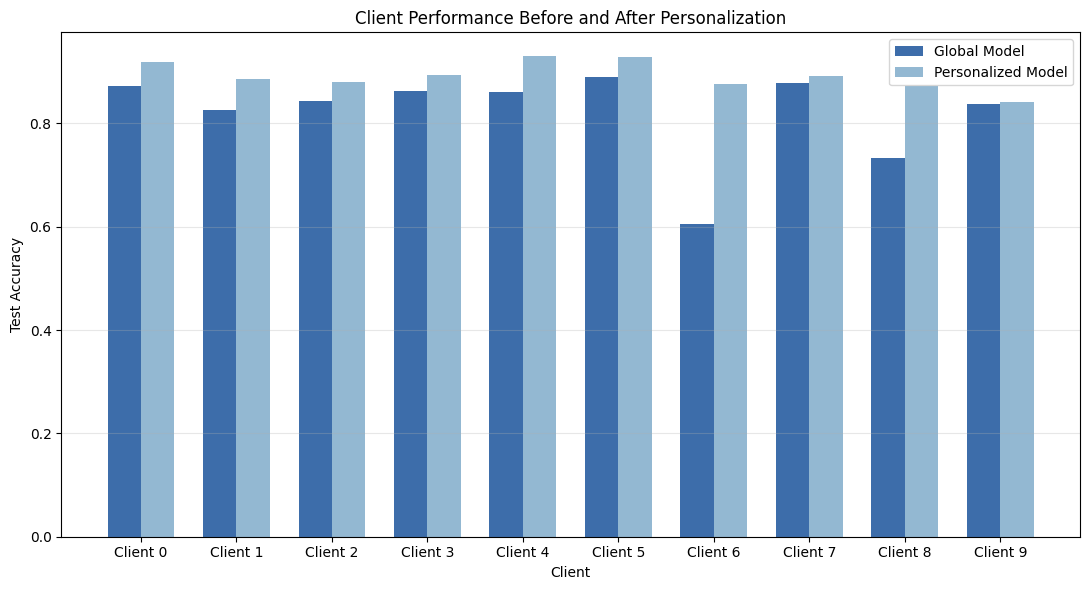

In [ ]:
# ============================================================
# CELL 43 — CLIENT-LEVEL PERSONALIZATION
# ============================================================

x = np.arange(
    NUM_CLIENTS
)

width = 0.35

plt.figure(
    figsize=(11, 6)
)

# Global Model
plt.bar(
    x - width / 2,
    personalization_results[
        "before_personalization"
    ],
    width,
    label="Global Model",
    color="#3d6daa"
)
# Personalized Model
plt.bar(
    x + width / 2,
    personalization_results[
        "after_personalization"
    ],
    width,
    label="Personalized Model",
    color="#93b8d2"
)

plt.xlabel(
    "Client"
)

plt.ylabel(
    "Test Accuracy"
)

plt.title(
    "Client Performance Before and After Personalization"
)

plt.xticks(
    x,
    [
        f"Client {i}"
        for i in range(NUM_CLIENTS)
    ]
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [62]:
# ============================================================
# CELL 44 — FULL PERSONALIZATION EXPERIMENT
# ============================================================

personalization_experiments = []

total_start = time.time()

for alpha in ALPHAS:

    print("\n")
    print("=" * 70)
    print(f"ALPHA = {alpha}")
    print("=" * 70)

    for run in range(NUM_RUNS):

        seed = SEED + run

        print(
            f"\nRun {run + 1}/{NUM_RUNS}"
        )

        # ----------------------------------------------------
        # Step 1: Train FedAvg
        # ----------------------------------------------------

        result = (
            run_fedavg_for_personalization(
                alpha=alpha,
                seed=seed
            )
        )

        # ----------------------------------------------------
        # Step 2: Get final global model
        # ----------------------------------------------------

        global_model = (
            result["global_model"]
        )

        global_state = (
            result["global_state"]
        )

        client_train_indices = (
            result["client_train_indices"]
        )

        client_test_indices = (
            result["client_test_indices"]
        )

        # ----------------------------------------------------
        # Step 3: Global accuracy
        # ----------------------------------------------------

        global_test_accuracy = (
            evaluate_model(
                global_model,
                X_test,
                y_test
            )
        )

        # ----------------------------------------------------
        # Step 4: Personalize every client
        # ----------------------------------------------------

        (
            personalized_models,
            client_results
        ) = personalize_all_clients(

            global_state=
                global_state,

            client_train_indices=
                client_train_indices,

            client_test_indices=
                client_test_indices
        )

        # ----------------------------------------------------
        # Step 5: Aggregate client results
        # ----------------------------------------------------

        mean_before = (
            client_results[
                "before_personalization"
            ].mean()
        )

        mean_after = (
            client_results[
                "after_personalization"
            ].mean()
        )

        worst_before = (
            client_results[
                "before_personalization"
            ].min()
        )

        worst_after = (
            client_results[
                "after_personalization"
            ].min()
        )

        mean_improvement = (
            client_results[
                "improvement"
            ].mean()
        )

        # ----------------------------------------------------
        # Store experiment
        # ----------------------------------------------------

        personalization_experiments.append({

            "alpha":
                alpha,

            "run":
                run,

            "global_accuracy":
                global_test_accuracy,

            "mean_client_before":
                mean_before,

            "mean_client_after":
                mean_after,

            "worst_client_before":
                worst_before,

            "worst_client_after":
                worst_after,

            "mean_personalization_improvement":
                mean_improvement
        })

        print(
            f"Global accuracy: "
            f"{global_test_accuracy:.4f}"
        )

        print(
            f"Client accuracy before: "
            f"{mean_before:.4f}"
        )

        print(
            f"Client accuracy after: "
            f"{mean_after:.4f}"
        )

        print(
            f"Improvement: "
            f"{mean_improvement:+.4f}"
        )

personalization_df = pd.DataFrame(
    personalization_experiments
)

total_elapsed = (
    time.time() - total_start
)

print(
    f"\nTotal time: "
    f"{total_elapsed / 60:.2f} minutes"
)



ALPHA = 0.1

Run 1/3
Global accuracy: 0.7710
Client accuracy before: 0.7603
Client accuracy after: 0.9402
Improvement: +0.1798

Run 2/3
Global accuracy: 0.7422
Client accuracy before: 0.6800
Client accuracy after: 0.9501
Improvement: +0.2701

Run 3/3
Global accuracy: 0.7999
Client accuracy before: 0.7819
Client accuracy after: 0.9262
Improvement: +0.1442


ALPHA = 0.3

Run 1/3
Global accuracy: 0.7929
Client accuracy before: 0.7429
Client accuracy after: 0.9103
Improvement: +0.1674

Run 2/3
Global accuracy: 0.8335
Client accuracy before: 0.8378
Client accuracy after: 0.9099
Improvement: +0.0721

Run 3/3
Global accuracy: 0.7845
Client accuracy before: 0.7497
Client accuracy after: 0.9116
Improvement: +0.1619


ALPHA = 0.5

Run 1/3
Global accuracy: 0.8335
Client accuracy before: 0.8209
Client accuracy after: 0.8912
Improvement: +0.0703

Run 2/3
Global accuracy: 0.8563
Client accuracy before: 0.8563
Client accuracy after: 0.8962
Improvement: +0.0398

Run 3/3
Global accuracy: 0.8447
Clien

In [63]:
# ============================================================
# CELL 45 — PERSONALIZATION RESULTS SUMMARY
# ============================================================

personalization_summary = (
    personalization_df
    .groupby("alpha")
    .agg(

        global_accuracy=(
            "global_accuracy",
            "mean"
        ),

        global_accuracy_std=(
            "global_accuracy",
            "std"
        ),

        mean_client_before=(
            "mean_client_before",
            "mean"
        ),

        mean_client_after=(
            "mean_client_after",
            "mean"
        ),

        worst_client_before=(
            "worst_client_before",
            "mean"
        ),

        worst_client_after=(
            "worst_client_after",
            "mean"
        ),

        mean_improvement=(
            "mean_personalization_improvement",
            "mean"
        ),

        improvement_std=(
            "mean_personalization_improvement",
            "std"
        )
    )
    .reset_index()
)

personalization_summary

,alpha,global_accuracy,global_accuracy_std,mean_client_before,mean_client_after,worst_client_before,worst_client_after,mean_improvement,improvement_std
0,0.1,0.771033,0.028850,0.740769,0.938831,0.373806,0.861109,0.198062,0.064882
1,0.3,0.803633,0.026204,0.776796,0.910582,0.540244,0.855851,0.133787,0.053528
2,0.5,0.844833,0.011401,0.840232,0.894433,0.691906,0.863080,0.054200,0.015321
3,1.0,0.853433,0.004908,0.846239,0.868596,0.800564,0.837144,0.022357,0.001348
4,5.0,0.853800,0.001908,0.847456,0.849679,0.824300,0.828102,0.002223,0.001721
5,10.0,0.852967,0.002485,0.841175,0.845044,0.810995,0.813029,0.003869,0.003263


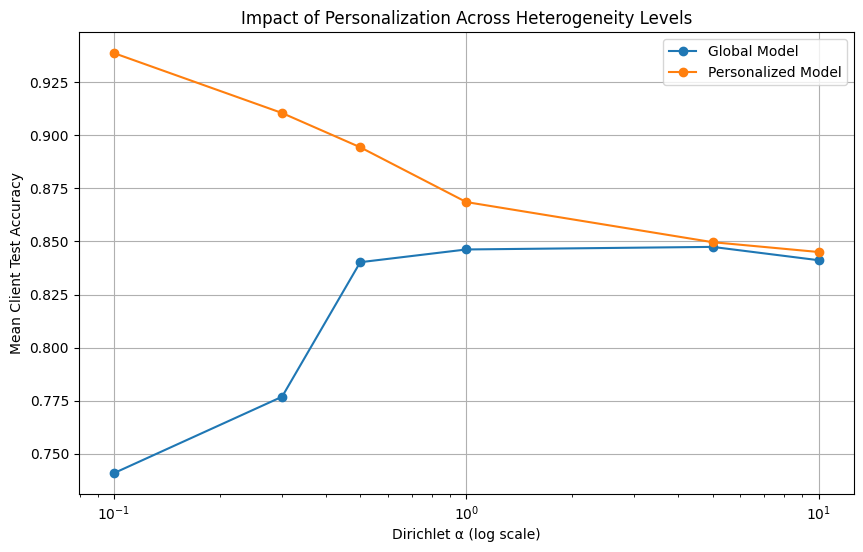

In [64]:
# ============================================================
# CELL 46 — PERSONALIZATION VS HETEROGENEITY
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    personalization_summary["alpha"],
    personalization_summary[
        "mean_client_before"
    ],
    marker="o",
    label="Global Model"
)

plt.plot(
    personalization_summary["alpha"],
    personalization_summary[
        "mean_client_after"
    ],
    marker="o",
    label="Personalized Model"
)

plt.xscale("log")

plt.xlabel(
    "Dirichlet α (log scale)"
)

plt.ylabel(
    "Mean Client Test Accuracy"
)

plt.title(
    "Impact of Personalization Across Heterogeneity Levels"
)

plt.grid(True)

plt.legend()

plt.show()

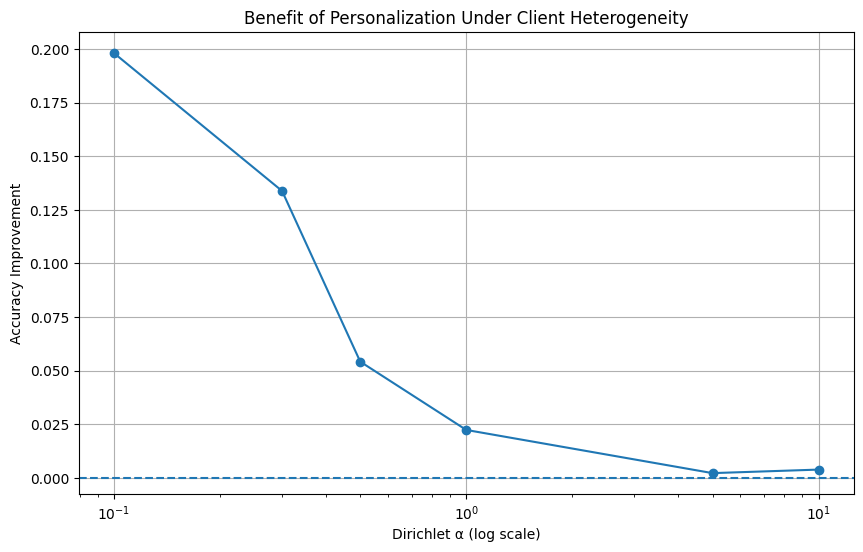

In [65]:
# ============================================================
# CELL 47 — PERSONALIZATION BENEFIT
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    personalization_summary["alpha"],
    personalization_summary[
        "mean_improvement"
    ],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xscale("log")

plt.xlabel(
    "Dirichlet α (log scale)"
)

plt.ylabel(
    "Accuracy Improvement"
)

plt.title(
    "Benefit of Personalization Under Client Heterogeneity"
)

plt.grid(True)

plt.show()

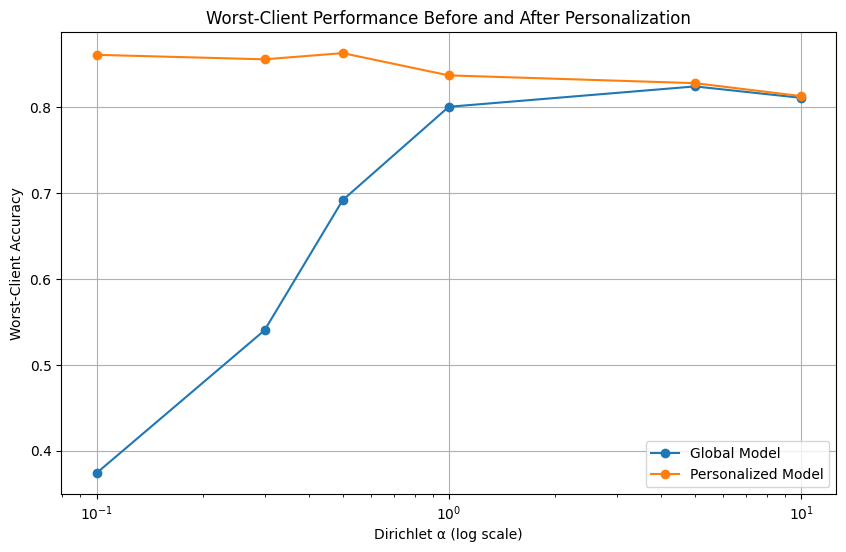

In [66]:
# ============================================================
# CELL 48 — WORST CLIENT PERFORMANCE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    personalization_summary["alpha"],
    personalization_summary[
        "worst_client_before"
    ],
    marker="o",
    label="Global Model"
)

plt.plot(
    personalization_summary["alpha"],
    personalization_summary[
        "worst_client_after"
    ],
    marker="o",
    label="Personalized Model"
)

plt.xscale("log")

plt.xlabel(
    "Dirichlet α (log scale)"
)

plt.ylabel(
    "Worst-Client Accuracy"
)

plt.title(
    "Worst-Client Performance Before and After Personalization"
)

plt.grid(True)

plt.legend()

plt.show()

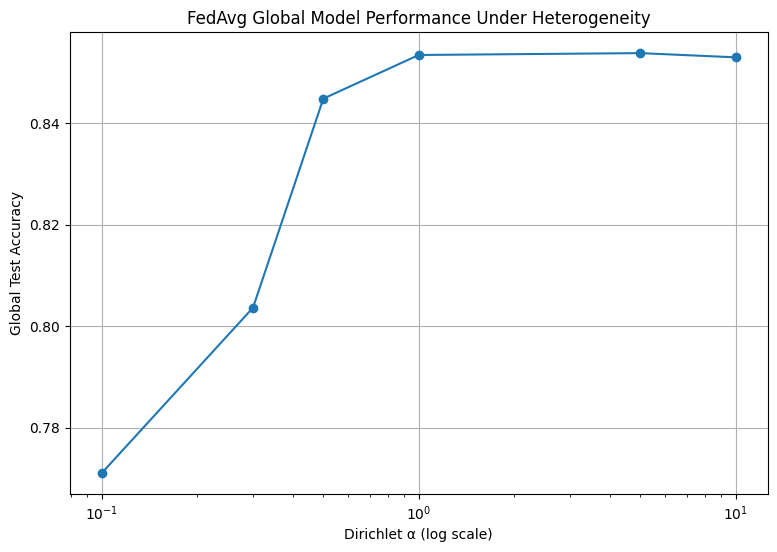

In [67]:
# ============================================================
# CELL 49 — GLOBAL MODEL PERFORMANCE
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    personalization_summary["alpha"],
    personalization_summary[
        "global_accuracy"
    ],
    marker="o"
)

plt.xscale("log")

plt.xlabel(
    "Dirichlet α (log scale)"
)

plt.ylabel(
    "Global Test Accuracy"
)

plt.title(
    "FedAvg Global Model Performance Under Heterogeneity"
)

plt.grid(True)

plt.show()

In [68]:
# ============================================================
# CELL 50 — FINAL RESEARCH TABLE
# ============================================================

final_personalization_results = (
    personalization_summary.copy()
)

final_personalization_results[
    "global_accuracy"
] = (
    final_personalization_results[
        "global_accuracy"
    ].round(4)
)

final_personalization_results[
    "mean_client_before"
] = (
    final_personalization_results[
        "mean_client_before"
    ].round(4)
)

final_personalization_results[
    "mean_client_after"
] = (
    final_personalization_results[
        "mean_client_after"
    ].round(4)
)

final_personalization_results[
    "worst_client_before"
] = (
    final_personalization_results[
        "worst_client_before"
    ].round(4)
)

final_personalization_results[
    "worst_client_after"
] = (
    final_personalization_results[
        "worst_client_after"
    ].round(4)
)

final_personalization_results[
    "mean_improvement"
] = (
    final_personalization_results[
        "mean_improvement"
    ].round(4)
)

final_personalization_results

,alpha,global_accuracy,global_accuracy_std,mean_client_before,mean_client_after,worst_client_before,worst_client_after,mean_improvement,improvement_std
0,0.1,0.7710,0.028850,0.7408,0.9388,0.3738,0.8611,0.1981,0.064882
1,0.3,0.8036,0.026204,0.7768,0.9106,0.5402,0.8559,0.1338,0.053528
2,0.5,0.8448,0.011401,0.8402,0.8944,0.6919,0.8631,0.0542,0.015321
3,1.0,0.8534,0.004908,0.8462,0.8686,0.8006,0.8371,0.0224,0.001348
4,5.0,0.8538,0.001908,0.8475,0.8497,0.8243,0.8281,0.0022,0.001721
5,10.0,0.8530,0.002485,0.8412,0.8450,0.8110,0.8130,0.0039,0.003263


In [69]:
# ============================================================
# CELL 51 — SAVE PERSONALIZATION RESULTS
# ============================================================

personalization_df.to_csv(
    "personalization_all_runs.csv",
    index=False
)

personalization_summary.to_csv(
    "personalization_summary.csv",
    index=False
)

final_personalization_results.to_csv(
    "final_personalization_results.csv",
    index=False
)

print(
    "Personalization results saved."
)

Personalization results saved.


**LET'S TRY OTHER METHODS**